07 : Use K-Medoids clustering to segment wholesale customers based on their annual spending on different
product categories. Identify the optimal number of clusters to effectively group customers with similar
purchasing behaviours. Dataset: Wholesale Customers Dataset (UCI).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from kmedoids import KMedoids

In [3]:
df = pd.read_csv('Wholesale_Customers.csv')
print("Dataset Shape :", df.shape)
df.head()

Dataset Shape : (440, 9)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,Cluster
0,2,3,12669,9656,7561,214,2674,1338,1
1,2,3,7057,9810,9568,1762,3293,1776,1
2,2,3,6353,8808,7684,2405,3516,7844,1
3,1,3,13265,1196,4221,6404,507,1788,1
4,2,3,22615,5410,7198,3915,1777,5185,1


In [4]:
if df.isnull().sum().sum() > 0:
  print("Missing Values Present")
  print(df.isnull().sum())
else :
  print("No Missing Values Found")

No Missing Values Found


In [5]:
df.columns

Index(['Channel', 'Region', 'Fresh', 'Milk', 'Grocery', 'Frozen',
       'Detergents_Paper', 'Delicassen', 'Cluster'],
      dtype='object')

In [6]:
x = df.drop(['Channel','Region', 'Cluster'], axis=1)
x.head()

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


In [7]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [12]:
scores = []

for k in range(2,8):
  model = KMedoids(
      n_clusters=k,
      method="pam",
      random_state=42
  )

  labels = model.fit_predict(x_scaled)

  score = silhouette_score(x_scaled, labels)

  scores.append(score)

  print("Clusters:", k, "Silhouette Score:", round(score, 4))

Clusters: 2 Silhouette Score: 0.4085
Clusters: 3 Silhouette Score: 0.322
Clusters: 4 Silhouette Score: 0.2507
Clusters: 5 Silhouette Score: 0.2392
Clusters: 6 Silhouette Score: 0.2462
Clusters: 7 Silhouette Score: 0.2308


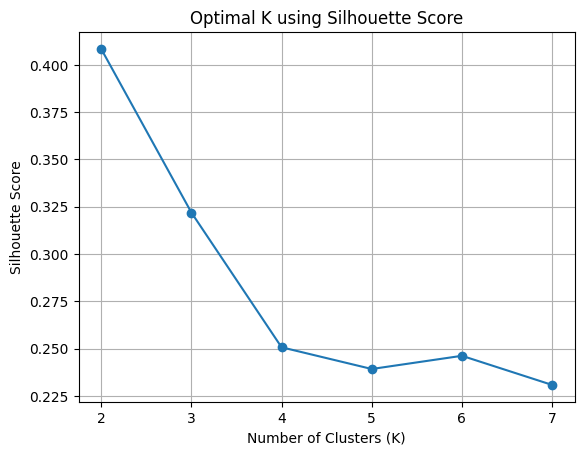

In [13]:
plt.plot(range(2, 8), scores, marker="o")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Optimal K using Silhouette Score")
plt.xticks(range(2, 8))
plt.grid()
plt.show()

In [14]:
best_k = range(2, 8)[np.argmax(scores)]
print("Optimal Number of Clusters:", best_k)

Optimal Number of Clusters: 2


In [16]:
kmedoids = KMedoids(
    n_clusters=best_k,
    random_state=42,
    method="pam"
)

df["Cluster"] = kmedoids.fit_predict(x_scaled)

In [18]:
print("\nCluster Counts :")
print(df["Cluster"].value_counts().sort_index())


Cluster Counts :
Cluster
0    107
1    333
Name: count, dtype: int64


In [22]:
features = [
  "Fresh", "Milk",
  "Grocery", "Frozen",
  "Detergents_Paper",
  "Delicassen"
]

In [23]:
print("\nAverage Spending by Cluster :")
print(df.groupby("Cluster")[features].mean().round(2))


Average Spending by Cluster :
            Fresh      Milk   Grocery   Frozen  Detergents_Paper  Delicassen
Cluster                                                                     
0         8359.74  13618.21  19798.03  2126.02           8798.78     2569.51
1        13170.09   3282.91   4144.66  3375.87            980.14     1189.20


In [24]:
pca = PCA(n_components=2)
x_pca = pca.fit_transform(x_scaled)

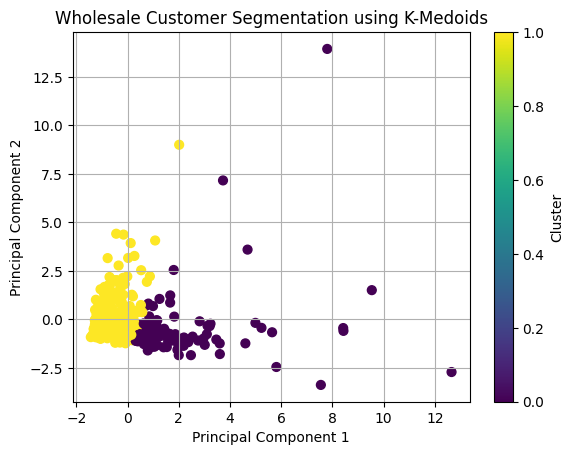

In [25]:
plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=df["Cluster"],
    cmap="viridis",
    s=40
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Wholesale Customer Segmentation using K-Medoids")
plt.colorbar(label="Cluster")
plt.grid()
plt.show()